# Student Performance Dataset – Data Preparation and Exploratory Analysis

This notebook prepares and explores the student performance dataset before machine learning model development.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load Dataset

In [2]:
data_path = Path("../data/raw/student_performance_dataset.csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (2000, 10)


,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities,Final_Exam_Score,Pass_Fail
0,S147,Male,31,68.267841,86,High School,Yes,Yes,63,Pass
1,S136,Male,16,78.222927,73,PhD,No,No,50,Fail
2,S209,Female,21,87.525096,74,PhD,Yes,No,55,Fail
3,S458,Female,27,92.076483,99,Bachelors,No,No,65,Pass
4,S078,Female,37,98.655517,63,Masters,No,Yes,70,Pass


## 2. Initial Dataset Inspection

In [3]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Rows and columns: (2000, 10)

Column names:
['Student_ID', 'Gender', 'Study_Hours_per_Week', 'Attendance_Rate', 'Past_Exam_Scores', 'Parental_Education_Level', 'Internet_Access_at_Home', 'Extracurricular_Activities', 'Final_Exam_Score', 'Pass_Fail']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  2000 non-null   str    
 1   Gender                      2000 non-null   str    
 2   Study_Hours_per_Week        2000 non-null   int64  
 3   Attendance_Rate             2000 non-null   float64
 4   Past_Exam_Scores            2000 non-null   int64  
 5   Parental_Education_Level    2000 non-null   str    
 6   Internet_Access_at_Home     2000 non-null   str    
 7   Extracurricular_Activities  2000 non-null   str    
 8   Final_Exam_Score            2000 non-null   int64  
 9   Pass_Fail                   2000 non-null   str    
dtypes: float64(1), int64(3), str(6)
memory usage: 207.8 KB


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,2000,1792,S339,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,2000,2,Female,1041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Study_Hours_per_Week,2000.0,NaN,NaN,NaN,26.1755,8.863745,10.0,19.0,27.0,34.0,39.0
Attendance_Rate,2000.0,NaN,NaN,NaN,78.126095,13.793072,50.11697,67.532746,79.262902,89.836661,99.967675
Past_Exam_Scores,2000.0,NaN,NaN,NaN,77.863,14.514323,50.0,65.0,79.0,91.0,100.0
Parental_Education_Level,2000,4,Bachelors,549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access_at_Home,2000,2,No,1039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,2000,2,No,1011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Final_Exam_Score,2000.0,NaN,NaN,NaN,58.84,6.048694,50.0,54.0,59.0,63.0,77.0
Pass_Fail,2000,2,Fail,1046,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data Quality Checks

This section examines the dataset for missing values, duplicate records, inconsistent values, and potential data quality issues before preprocessing.

### 3.1 Missing Values

In [6]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Student_ID                    0
Gender                        0
Study_Hours_per_Week          0
Attendance_Rate               0
Past_Exam_Scores              0
Parental_Education_Level      0
Internet_Access_at_Home       0
Extracurricular_Activities    0
Final_Exam_Score              0
Pass_Fail                     0
dtype: int64

Total missing values: 0


### 3.2 Duplicate Records

In [7]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 208


In [8]:
df[df.duplicated(keep=False)].sort_values(by="Student_ID").head(20)

,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities,Final_Exam_Score,Pass_Fail
237,S011,Male,12,84.585720,80,High School,No,Yes,60,Pass
510,S011,Male,12,84.585720,80,High School,No,Yes,60,Pass
192,S016,Male,24,86.306042,91,High School,Yes,Yes,65,Pass
210,S016,Male,24,86.306042,91,High School,Yes,Yes,65,Pass
247,S017,Female,31,87.854060,88,Masters,Yes,No,65,Pass
250,S017,Female,31,87.854060,88,Masters,Yes,No,65,Pass
397,S017,Female,31,87.854060,88,Masters,Yes,No,65,Pass
587,S017,Female,31,87.854060,88,Masters,Yes,No,65,Pass
193,S023,Female,35,60.361382,93,Bachelors,No,No,63,Pass
270,S023,Female,35,60.361382,93,Bachelors,No,No,63,Pass


### 3.3 Duplicate Student IDs

In [9]:
duplicate_ids = df["Student_ID"].duplicated().sum()

print("Number of repeated Student IDs:", duplicate_ids)

Number of repeated Student IDs: 208


In [10]:
df[df["Student_ID"].duplicated(keep=False)].sort_values(by="Student_ID").head(20)

,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities,Final_Exam_Score,Pass_Fail
237,S011,Male,12,84.585720,80,High School,No,Yes,60,Pass
510,S011,Male,12,84.585720,80,High School,No,Yes,60,Pass
192,S016,Male,24,86.306042,91,High School,Yes,Yes,65,Pass
210,S016,Male,24,86.306042,91,High School,Yes,Yes,65,Pass
247,S017,Female,31,87.854060,88,Masters,Yes,No,65,Pass
250,S017,Female,31,87.854060,88,Masters,Yes,No,65,Pass
397,S017,Female,31,87.854060,88,Masters,Yes,No,65,Pass
587,S017,Female,31,87.854060,88,Masters,Yes,No,65,Pass
193,S023,Female,35,60.361382,93,Bachelors,No,No,63,Pass
270,S023,Female,35,60.361382,93,Bachelors,No,No,63,Pass


### 3.4 Categorical Values

In [11]:
categorical_columns = [
    "Gender",
    "Parental_Education_Level",
    "Internet_Access_at_Home",
    "Extracurricular_Activities",
    "Pass_Fail"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())


Gender:
Gender
Female    1041
Male       959
Name: count, dtype: int64

Parental_Education_Level:
Parental_Education_Level
Bachelors      549
High School    511
Masters        493
PhD            447
Name: count, dtype: int64

Internet_Access_at_Home:
Internet_Access_at_Home
No     1039
Yes     961
Name: count, dtype: int64

Extracurricular_Activities:
Extracurricular_Activities
No     1011
Yes     989
Name: count, dtype: int64

Pass_Fail:
Pass_Fail
Fail    1046
Pass     954
Name: count, dtype: int64


### 3.5 Numerical Value Ranges

In [12]:
numerical_columns = [
    "Study_Hours_per_Week",
    "Attendance_Rate",
    "Past_Exam_Scores",
    "Final_Exam_Score"
]

df[numerical_columns].agg(["min", "max", "mean", "median", "std"]).T

,min,max,mean,median,std
Study_Hours_per_Week,10.00000,39.000000,26.175500,27.000000,8.863745
Attendance_Rate,50.11697,99.967675,78.126095,79.262902,13.793072
Past_Exam_Scores,50.00000,100.000000,77.863000,79.000000,14.514323
Final_Exam_Score,50.00000,77.000000,58.840000,59.000000,6.048694


### 3.6 Target Variable Consistency

In [13]:
pd.crosstab(
    df["Final_Exam_Score"],
    df["Pass_Fail"]
)

Pass_Fail,Fail,Pass
Final_Exam_Score,,
50,283,0
51,52,0
52,69,0
53,73,0
54,78,0
55,98,0
56,84,0
57,110,0
58,93,0


In [14]:
print("Final scores for Fail:")
print(df.loc[df["Pass_Fail"] == "Fail", "Final_Exam_Score"].agg(["min", "max"]))

print("\nFinal scores for Pass:")
print(df.loc[df["Pass_Fail"] == "Pass", "Final_Exam_Score"].agg(["min", "max"]))

Final scores for Fail:
min    50
max    59
Name: Final_Exam_Score, dtype: int64

Final scores for Pass:
min    60
max    77
Name: Final_Exam_Score, dtype: int64


### 3.7 Correlation Check

In [15]:
correlation_matrix = df[
    [
        "Study_Hours_per_Week",
        "Attendance_Rate",
        "Past_Exam_Scores",
        "Final_Exam_Score"
    ]
].corr()

correlation_matrix.round(3)

,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Final_Exam_Score
Study_Hours_per_Week,1.000,-0.005,-0.005,0.357
Attendance_Rate,-0.005,1.000,0.032,0.454
Past_Exam_Scores,-0.005,0.032,1.000,0.511
Final_Exam_Score,0.357,0.454,0.511,1.000


In [16]:
print("Correlation with Final Exam Score:")
print(
    correlation_matrix["Final_Exam_Score"]
    .sort_values(ascending=False)
    .round(3)
)

Correlation with Final Exam Score:
Final_Exam_Score        1.000
Past_Exam_Scores        0.511
Attendance_Rate         0.454
Study_Hours_per_Week    0.357
Name: Final_Exam_Score, dtype: float64


## 4. Data Cleaning

Based on the initial data quality assessment, duplicate records, non-predictive identifiers, and variables that could introduce target leakage are addressed before further analysis and model development.

### 4.1 Create Working Copy

In [17]:
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (2000, 10)
Working dataset shape: (2000, 10)


### 4.2 Remove Duplicate Records

In [18]:
rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

rows_after = len(df_clean)

print("Rows before duplicate removal:", rows_before)
print("Rows after duplicate removal:", rows_after)
print("Duplicate rows removed:", rows_before - rows_after)

Rows before duplicate removal: 2000
Rows after duplicate removal: 1792
Duplicate rows removed: 208


In [19]:
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Remaining duplicate rows: 0


### 4.3 Remove Identifier Variable

In [20]:
df_clean = df_clean.drop(columns=["Student_ID"])

print("Student_ID removed.")
print("Remaining columns:")
print(df_clean.columns.tolist())

Student_ID removed.
Remaining columns:
['Gender', 'Study_Hours_per_Week', 'Attendance_Rate', 'Past_Exam_Scores', 'Parental_Education_Level', 'Internet_Access_at_Home', 'Extracurricular_Activities', 'Final_Exam_Score', 'Pass_Fail']


### 4.4 Remove Target Leakage Variable

In [21]:
df_clean = df_clean.drop(columns=["Final_Exam_Score"])

print("Final_Exam_Score removed to prevent target leakage.")
print("Remaining columns:")
print(df_clean.columns.tolist())

Final_Exam_Score removed to prevent target leakage.
Remaining columns:
['Gender', 'Study_Hours_per_Week', 'Attendance_Rate', 'Past_Exam_Scores', 'Parental_Education_Level', 'Internet_Access_at_Home', 'Extracurricular_Activities', 'Pass_Fail']


### 4.5 Select Final Prediction Variables

The final prediction dataset retains three academically relevant predictor variables: weekly study hours, attendance rate, and past exam scores. Pass/Fail is retained as the target variable.

In [22]:
model_columns = [
    "Study_Hours_per_Week",
    "Attendance_Rate",
    "Past_Exam_Scores",
    "Pass_Fail"
]

df_model = df_clean[model_columns].copy()

print("Variables retained for modelling:")
print(df_model.columns.tolist())

print("\nDataset shape:", df_model.shape)

df_model.head()

Variables retained for modelling:
['Study_Hours_per_Week', 'Attendance_Rate', 'Past_Exam_Scores', 'Pass_Fail']

Dataset shape: (1792, 4)


,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Pass_Fail
0,31,68.267841,86,Pass
1,16,78.222927,73,Fail
2,21,87.525096,74,Fail
3,27,92.076483,99,Pass
4,37,98.655517,63,Pass


### 4.6 Final Data Quality Verification

In [23]:
print("Final modelling dataset shape:", df_model.shape)

print("\nMissing values:")
print(df_model.isnull().sum())

print("\nData types:")
print(df_model.dtypes)

print("\nTarget distribution:")
print(df_model["Pass_Fail"].value_counts())

Final modelling dataset shape: (1792, 4)

Missing values:
Study_Hours_per_Week    0
Attendance_Rate         0
Past_Exam_Scores        0
Pass_Fail               0
dtype: int64

Data types:
Study_Hours_per_Week      int64
Attendance_Rate         float64
Past_Exam_Scores          int64
Pass_Fail                   str
dtype: object

Target distribution:
Pass_Fail
Fail    1046
Pass     746
Name: count, dtype: int64


In [24]:
df_model.describe()

,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores
count,1792.000000,1792.000000,1792.000000
mean,25.915737,77.492895,77.121652
std,8.853365,13.877129,14.586492
min,10.000000,50.116970,50.000000
25%,19.000000,66.998832,64.000000
50%,27.000000,78.530904,78.000000
75%,34.000000,89.387279,90.000000
max,39.000000,99.967675,100.000000


## 5. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the distributions of the selected variables and examine their relationships with the Pass/Fail target before model development.

### 5.1 Pass/Fail Distribution

In [25]:
target_counts = df_model["Pass_Fail"].value_counts()
target_percentages = df_model["Pass_Fail"].value_counts(normalize=True) * 100

print("Target counts:")
print(target_counts)

print("\nTarget percentages:")
print(target_percentages.round(2))

Target counts:
Pass_Fail
Fail    1046
Pass     746
Name: count, dtype: int64

Target percentages:
Pass_Fail
Fail    58.37
Pass    41.63
Name: proportion, dtype: float64


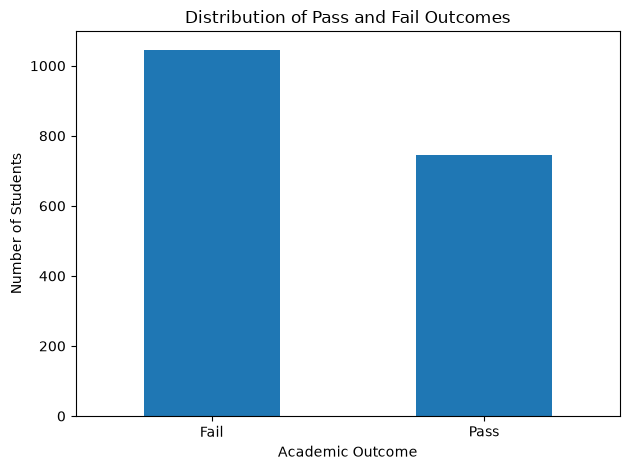

In [26]:
target_counts.plot(kind="bar")

plt.title("Distribution of Pass and Fail Outcomes")
plt.xlabel("Academic Outcome")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.2 Distribution of Weekly Study Hours

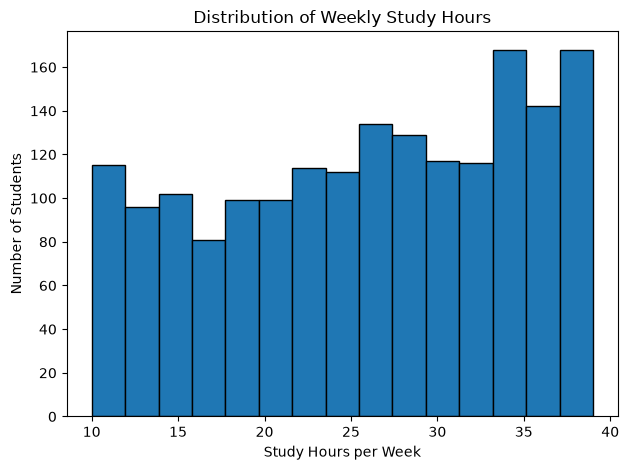

In [27]:
plt.hist(df_model["Study_Hours_per_Week"], bins=15, edgecolor="black")

plt.title("Distribution of Weekly Study Hours")
plt.xlabel("Study Hours per Week")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [28]:
df_model["Study_Hours_per_Week"].describe()

count    1792.000000
mean       25.915737
std         8.853365
min        10.000000
25%        19.000000
50%        27.000000
75%        34.000000
max        39.000000
Name: Study_Hours_per_Week, dtype: float64

### 5.3 Distribution of Attendance Rate

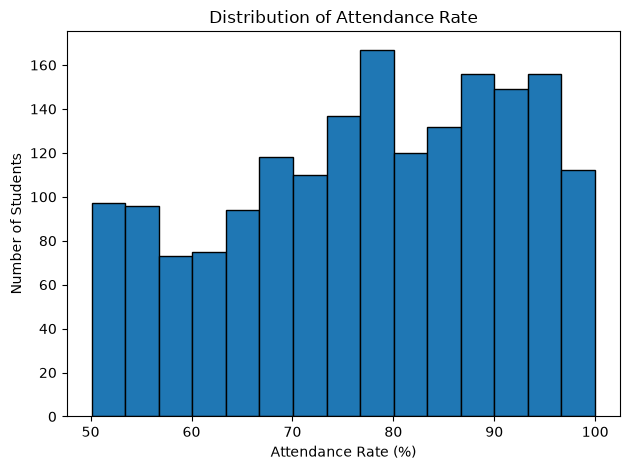

In [29]:
plt.hist(df_model["Attendance_Rate"], bins=15, edgecolor="black")

plt.title("Distribution of Attendance Rate")
plt.xlabel("Attendance Rate (%)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [30]:
df_model["Attendance_Rate"].describe()

count    1792.000000
mean       77.492895
std        13.877129
min        50.116970
25%        66.998832
50%        78.530904
75%        89.387279
max        99.967675
Name: Attendance_Rate, dtype: float64

### 5.4 Distribution of Past Exam Scores

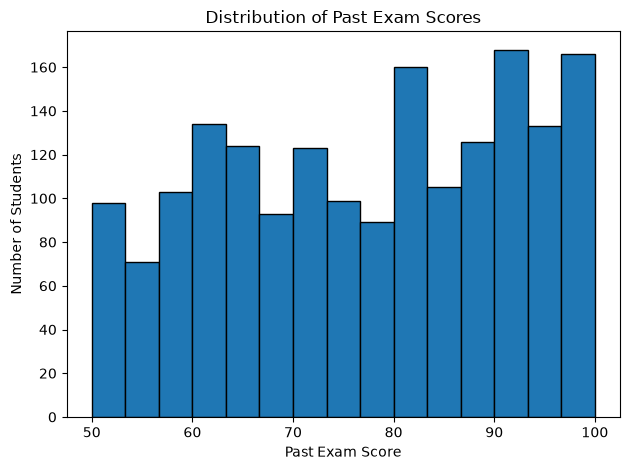

In [31]:
plt.hist(df_model["Past_Exam_Scores"], bins=15, edgecolor="black")

plt.title("Distribution of Past Exam Scores")
plt.xlabel("Past Exam Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [32]:
df_model["Past_Exam_Scores"].describe()

count    1792.000000
mean       77.121652
std        14.586492
min        50.000000
25%        64.000000
50%        78.000000
75%        90.000000
max       100.000000
Name: Past_Exam_Scores, dtype: float64

### 5.5 Predictor Comparison by Academic Outcome

In [33]:
outcome_summary = df_model.groupby("Pass_Fail")[
    [
        "Study_Hours_per_Week",
        "Attendance_Rate",
        "Past_Exam_Scores"
    ]
].mean()

outcome_summary.round(2)

,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores
Pass_Fail,,,
Fail,23.73,73.15,71.63
Pass,28.98,83.58,84.82


### 5.6 Study Hours by Academic Outcome

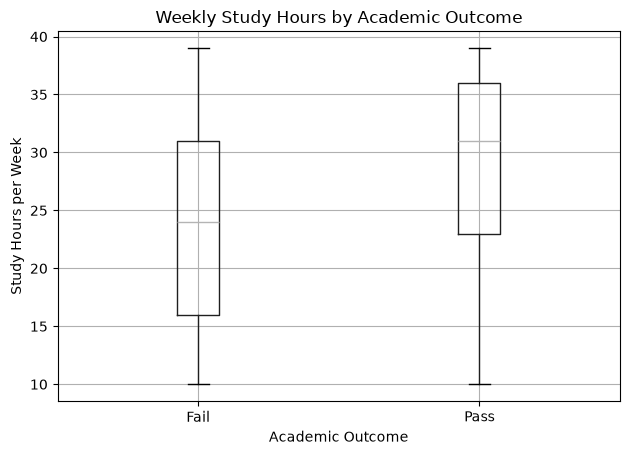

In [34]:
df_model.boxplot(
    column="Study_Hours_per_Week",
    by="Pass_Fail"
)

plt.title("Weekly Study Hours by Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("Study Hours per Week")
plt.tight_layout()
plt.show()

### 5.7 Attendance Rate by Academic Outcome

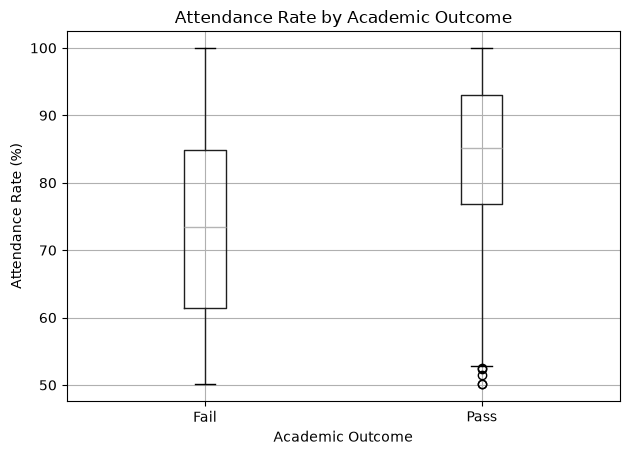

In [35]:
df_model.boxplot(
    column="Attendance_Rate",
    by="Pass_Fail"
)

plt.title("Attendance Rate by Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("Attendance Rate (%)")
plt.tight_layout()
plt.show()

### 5.8 Past Exam Scores by Academic Outcome

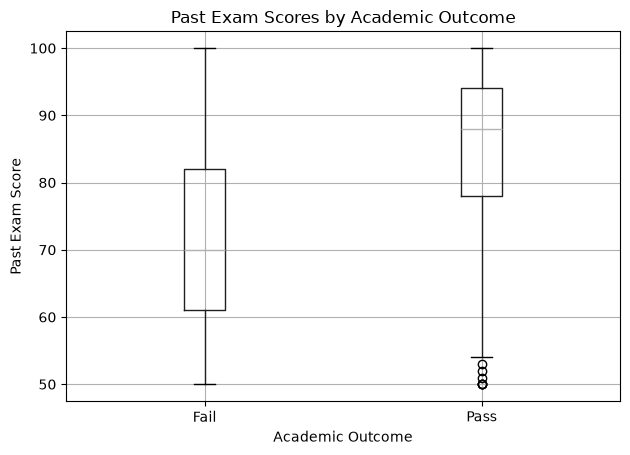

In [36]:
df_model.boxplot(
    column="Past_Exam_Scores",
    by="Pass_Fail"
)

plt.title("Past Exam Scores by Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("Past Exam Score")
plt.tight_layout()
plt.show()

### 5.9 Correlation Analysis of Final Variables

The Pass/Fail target is temporarily encoded numerically to examine its relationship with the selected predictor variables. Pass is represented as 1 and Fail as 0.

In [37]:
correlation_data = df_model.copy()

correlation_data["Pass_Fail_Encoded"] = (
    correlation_data["Pass_Fail"].map({
        "Fail": 0,
        "Pass": 1
    })
)

correlation_matrix_final = correlation_data[
    [
        "Study_Hours_per_Week",
        "Attendance_Rate",
        "Past_Exam_Scores",
        "Pass_Fail_Encoded"
    ]
].corr()

correlation_matrix_final.round(3)

,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Pass_Fail_Encoded
Study_Hours_per_Week,1.000,-0.009,0.001,0.292
Attendance_Rate,-0.009,1.000,0.035,0.370
Past_Exam_Scores,0.001,0.035,1.000,0.446
Pass_Fail_Encoded,0.292,0.370,0.446,1.000


In [38]:
print("Correlation with Pass/Fail:")

print(
    correlation_matrix_final["Pass_Fail_Encoded"]
    .sort_values(ascending=False)
    .round(3)
)

Correlation with Pass/Fail:
Pass_Fail_Encoded       1.000
Past_Exam_Scores        0.446
Attendance_Rate         0.370
Study_Hours_per_Week    0.292
Name: Pass_Fail_Encoded, dtype: float64


## 6. EDA Summary

The exploratory analysis showed that all three selected predictor variables were positively associated with academic outcome. Past exam scores demonstrated the strongest correlation with Pass/Fail (0.446), followed by attendance rate (0.370) and weekly study hours (0.292).

Students who passed also demonstrated higher average past exam scores, attendance rates, and weekly study hours than students who failed. The predictors showed very low correlations with one another, indicating that they capture different aspects of student academic behaviour and performance.

Based on these findings, Study_Hours_per_Week, Attendance_Rate, and Past_Exam_Scores were retained as the final predictor variables for machine learning model development, with Pass_Fail used as the target variable.

## 7. Save Processed Dataset

In [39]:
output_path = "../data/processed/student_performance_processed.csv"

df_model.to_csv(output_path, index=False)

print("Processed dataset saved successfully.")
print("Location:", output_path)
print("Shape:", df_model.shape)

Processed dataset saved successfully.
Location: ../data/processed/student_performance_processed.csv
Shape: (1792, 4)
